# Praktikum 2 - Klasifikasi SVM dengan Data Dummy Non-Linier

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Kelas:** TI-3G  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---


## Langkah 1a - Import Library

In [1]:
# import library
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
from sklearn.svm import SVC

## Langkah 1b - Buat Kembali Fungsi Plotting

In [2]:
# buat sebuah fungsi untuk menampilkan fitting data
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X = np.meshgrid(y, x)
    xy = np.vstack([X.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X.shape)

    # plot batas dan margin
    ax.contour(X, Y, P, colors='k',
               levels=[-1, 0, 1], alpha=0.5,
               linestyles=['--', '-', '--'])

    # plot support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0],
                   model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none');
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

## Langkah 1c - Buat Data Dummy Non-Linier

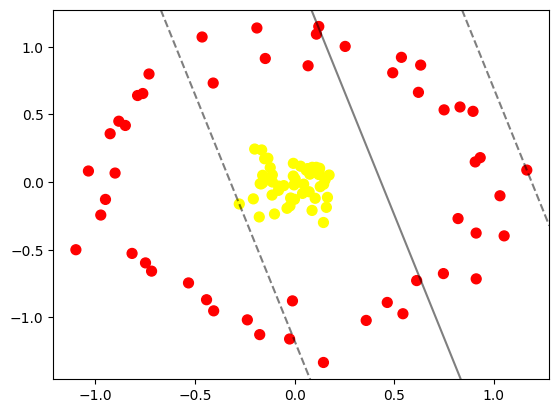

In [3]:
# contoh data tidak terpisah secara linier
from sklearn.datasets import make_circles
X, y = make_circles(100, factor=.1, noise=.1, random_state=0)

clf = SVC(kernel='linear').fit(X, y)

plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf, plot_support=False)
plt.show()

In [4]:
print('Akurasi SVM kernel linear pada data lingkaran:', clf.score(X, y))

Akurasi SVM kernel linear pada data lingkaran: 0.68


Data `make_circles` membentuk satu kelas di tengah dan kelas lainnya melingkar di sekelilingnya, jadi tidak ada garis lurus yang bisa memisahkan keduanya. Hasilnya terlihat pada plot, garis keputusan SVM kernel linear hanya memotong data secara lurus dan akurasinya cuma `0.68`. Angka ini tidak jauh dari tebakan acak untuk dua kelas seimbang (`0.50`), yang menunjukkan bahwa model linear memang tidak cocok untuk bentuk data seperti ini.

Proyeksi radial yang dipakai untuk menambah dimensi ketiga adalah

$$r = \exp\left(-\sum_i x_i^2\right)$$

In [5]:
r = np.exp(-(X ** 2).sum(1))

Jobsheet memakai `ipywidgets.interact` untuk memutar plot 3D. Di sini saya tampilkan empat sudut pandang (`elev`, `azim`) sekaligus supaya tidak perlu widget.

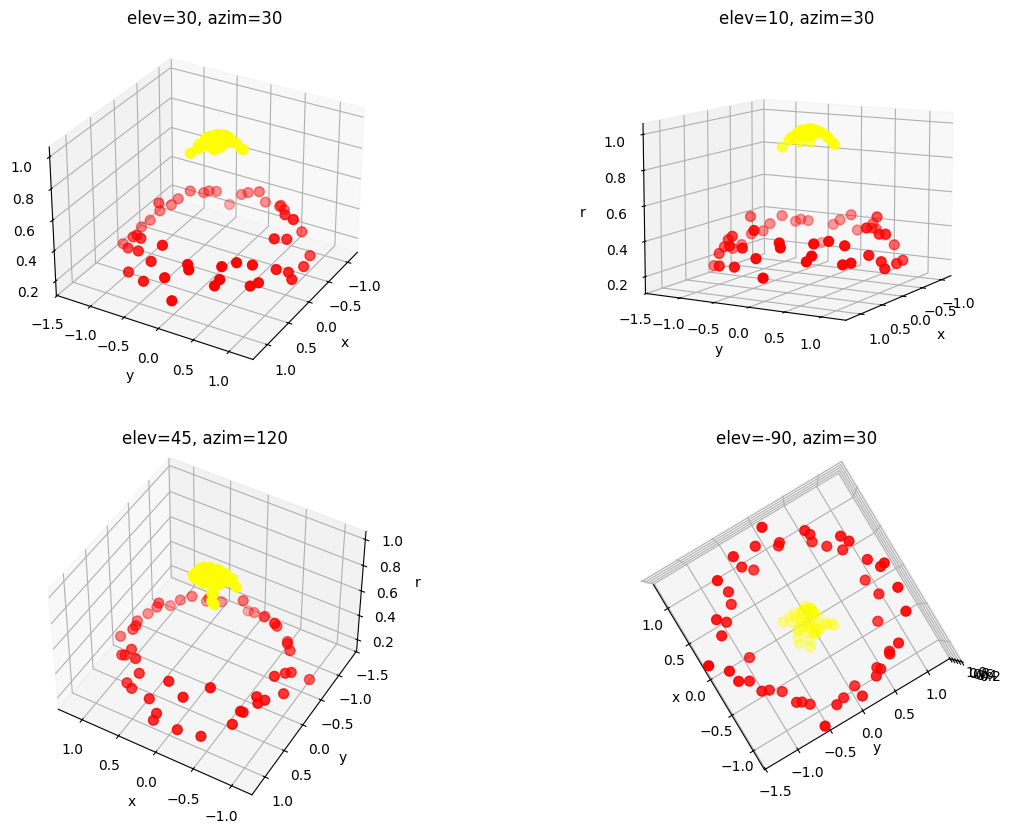

In [6]:
from mpl_toolkits import mplot3d

def plot_3D(elev=30, azim=30, X=X, y=y, ax=None):
    if ax is None:
        ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    ax.set_title(f'elev={elev}, azim={azim}')

fig = plt.figure(figsize=(14, 10))
for i, (elev, azim) in enumerate([(30, 30), (10, 30), (45, 120), (-90, 30)], start=1):
    ax = fig.add_subplot(2, 2, i, projection='3d')
    plot_3D(elev=elev, azim=azim, ax=ax)
plt.show()

Setelah ditambahkan dimensi ketiga $r = \exp(-\sum x_i^2)$, kedua kelas menjadi terpisah dengan jelas pada plot 3D. Titik-titik di pusat lingkaran punya jarak ke asal yang sangat kecil sehingga nilai $r$-nya mendekati 1 dan berada di bagian atas, sedangkan titik-titik pada cincin luar mempunyai $r$ yang jauh lebih kecil dan berada di bagian bawah. Di ruang tiga dimensi ini, sebuah bidang datar horizontal sudah cukup untuk memisahkan kedua kelas, padahal di ruang dua dimensi tidak ada garis lurus yang bisa melakukannya. Inilah gagasan di balik kernel trick.

## Langkah 2 - Fitting Model

In [7]:
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

,C,1000000.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


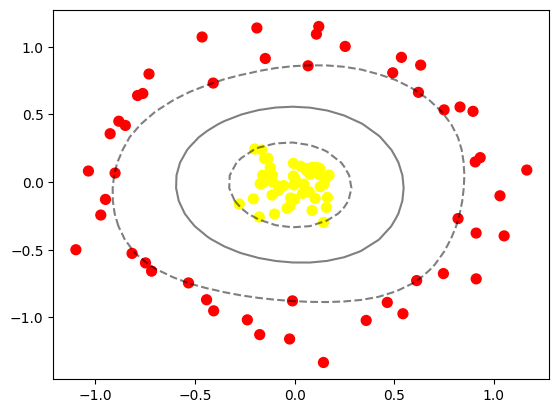

In [8]:
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.show()

In [9]:
print('Akurasi SVM kernel RBF pada data lingkaran :', clf.score(X, y))
print('Jumlah support vector per kelas           :', clf.n_support_)
print('Jumlah support vector total               :', len(clf.support_vectors_))

Akurasi SVM kernel RBF pada data lingkaran : 1.0
Jumlah support vector per kelas           : [8 2]
Jumlah support vector total               : 10


## Kesimpulan Praktikum 2

SVM kernel RBF berhasil memisahkan data lingkaran dengan akurasi `1.0`, jauh lebih baik dibanding kernel linear yang hanya `0.68` pada data yang sama. Batas keputusannya berbentuk lingkaran yang mengelilingi kelas di tengah, dan hanya `10` titik (`8` dari satu kelas dan `2` dari kelas lainnya) yang menjadi support vector. Kernel RBF mendapatkan efek yang sama seperti proyeksi radial pada plot 3D, tetapi tanpa perlu benar-benar menghitung dimensi tambahan tersebut sehingga komputasinya jauh lebih ringan.